In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("car data.csv")
df

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [3]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
df.shape

(301, 9)

In [5]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [7]:
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(2)

In [10]:
df.dtypes

Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type         object
Seller_Type       object
Transmission      object
Owner              int64
dtype: object

In [11]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [15]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
296    False
297    False
298    False
299    False
300    False
Length: 299, dtype: bool

In [16]:
len(df)

299

In [12]:
df = df.drop_duplicates()

In [13]:
df.shape

(299, 9)

In [17]:
df["Fuel_Type"].unique()

array(['Petrol', 'Diesel', 'CNG'], dtype=object)

In [18]:
df["Seller_Type"].unique()

array(['Dealer', 'Individual'], dtype=object)

In [19]:
df["Transmission"].unique()

array(['Manual', 'Automatic'], dtype=object)

In [20]:
df["Owner"].unique()

array([0, 1, 3])

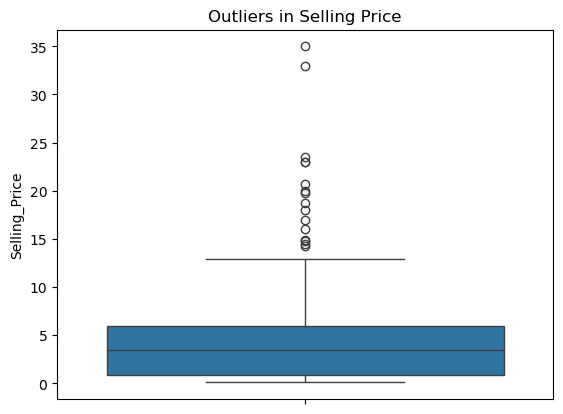

In [21]:
sns.boxplot(y=df["Selling_Price"])
plt.title("Outliers in Selling Price")
plt.show()

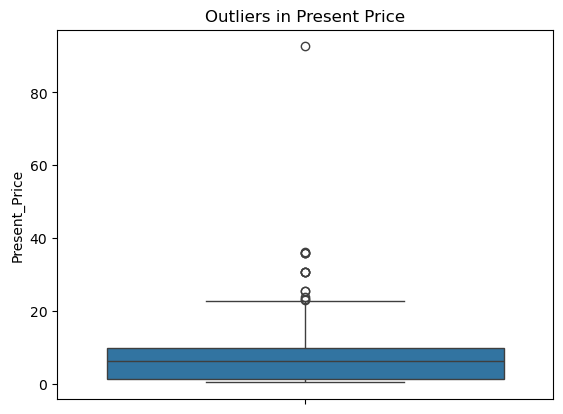

In [22]:
sns.boxplot(y=df["Present_Price"])
plt.title("Outliers in Present Price")
plt.show()

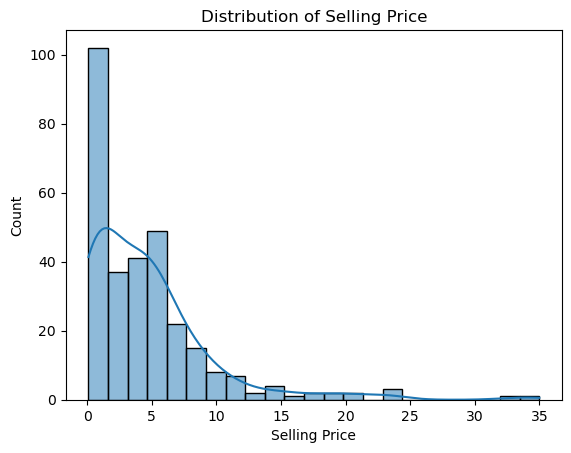

In [23]:
sns.histplot(df["Selling_Price"], kde=True)
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.show()

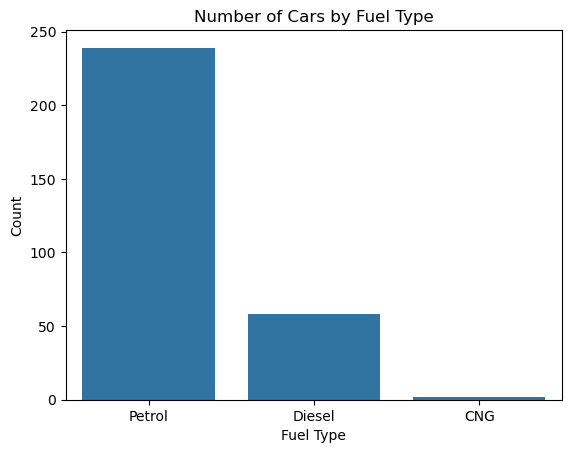

In [24]:
sns.countplot(x="Fuel_Type", data=df)
plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.show()

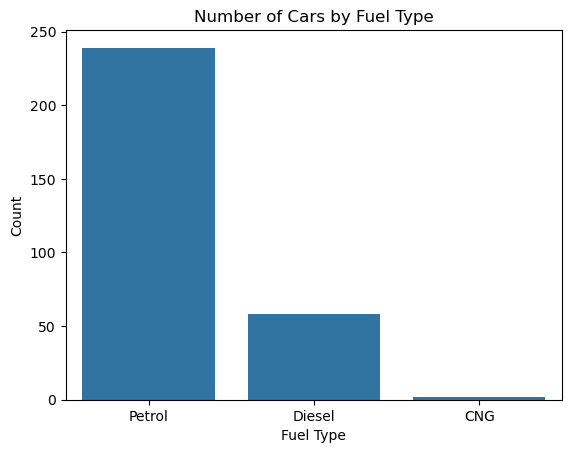

In [25]:
sns.countplot(x="Fuel_Type", data=df)
plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.show()

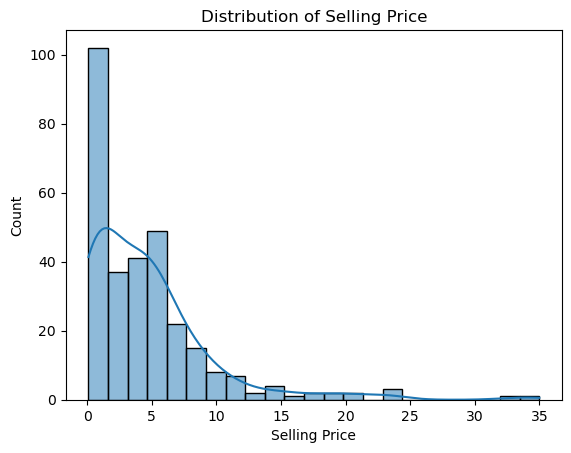

In [26]:
sns.histplot(df["Selling_Price"], kde=True)
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.show()

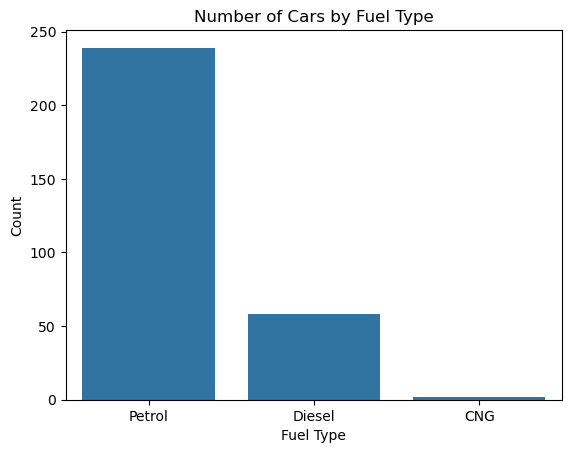

In [27]:
sns.countplot(x="Fuel_Type", data=df)
plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.show()

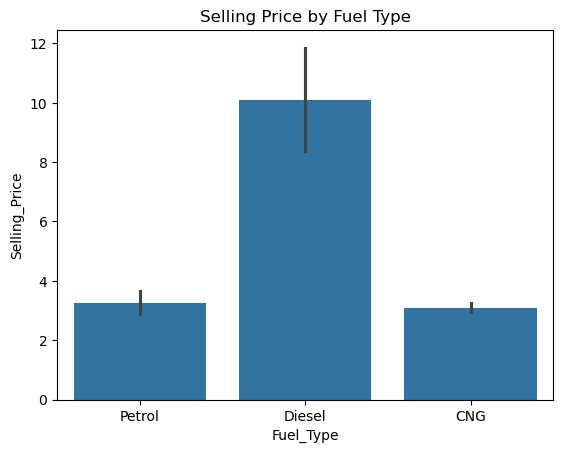

In [28]:
sns.barplot(x="Fuel_Type", y="Selling_Price", data=df)
plt.title("Selling Price by Fuel Type")
plt.show()

In [29]:
df.drop(columns=["Car_Name"], inplace=True)

df.head()

C:\Users\User\AppData\Local\Temp\ipykernel_30120\360681939.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=["Car_Name"], inplace=True)


,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [30]:
df["Fuel_Type"] = df["Fuel_Type"].map({
    "Petrol": 0,
    "Diesel": 1,
    "CNG": 2
})

df["Seller_Type"] = df["Seller_Type"].map({
    "Dealer": 0,
    "Individual": 1
})

df["Transmission"] = df["Transmission"].map({
    "Manual": 0,
    "Automatic": 1
})

df.head()

C:\Users\User\AppData\Local\Temp\ipykernel_30120\3532680251.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Fuel_Type"] = df["Fuel_Type"].map({
C:\Users\User\AppData\Local\Temp\ipykernel_30120\3532680251.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Seller_Type"] = df["Seller_Type"].map({
C:\Users\User\AppData\Local\Temp\ipykernel_30120\3532680251.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = val

,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,3.35,5.59,27000,0,0,0,0
1,2013,4.75,9.54,43000,1,0,0,0
2,2017,7.25,9.85,6900,0,0,0,0
3,2011,2.85,4.15,5200,0,0,0,0
4,2014,4.60,6.87,42450,1,0,0,0


In [31]:
X = df.drop("Selling_Price", axis=1)
Y = df["Selling_Price"]

In [32]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(239, 7)
(60, 7)


In [33]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [34]:
lr = LinearRegression()
lr.fit(X_train, Y_train)

Y_pred_lr = lr.predict(X_test)

print("MAE:", mean_absolute_error(Y_test, Y_pred_lr))
print("MSE:", mean_squared_error(Y_test, Y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, Y_pred_lr)))
print("R2 Score:", r2_score(Y_test, Y_pred_lr))

MAE: 1.5410718122837628
MSE: 6.67313744682826
RMSE: 2.583241654748595
R2 Score: 0.7410829335731296


In [35]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, Y_train)

Y_pred_dt = dt.predict(X_test)

print("MAE:", mean_absolute_error(Y_test, Y_pred_dt))
print("MSE:", mean_squared_error(Y_test, Y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, Y_pred_dt)))
print("R2 Score:", r2_score(Y_test, Y_pred_dt))

MAE: 1.0836666666666663
MSE: 4.164563333333333
RMSE: 2.0407261779409143
R2 Score: 0.8384153586214413


In [36]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, Y_train)

Y_pred_rf = rf.predict(X_test)

print("MAE:", mean_absolute_error(Y_test, Y_pred_rf))
print("MSE:", mean_squared_error(Y_test, Y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, Y_pred_rf)))
print("R2 Score:", r2_score(Y_test, Y_pred_rf))

MAE: 1.4787366666666677
MSE: 12.332645726666676
RMSE: 3.5117866858148825
R2 Score: 0.5214945775846247


In [37]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [
        mean_absolute_error(Y_test, Y_pred_lr),
        mean_absolute_error(Y_test, Y_pred_dt),
        mean_absolute_error(Y_test, Y_pred_rf)
    ],
    "MSE": [
        mean_squared_error(Y_test, Y_pred_lr),
        mean_squared_error(Y_test, Y_pred_dt),
        mean_squared_error(Y_test, Y_pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test, Y_pred_lr)),
        np.sqrt(mean_squared_error(Y_test, Y_pred_dt)),
        np.sqrt(mean_squared_error(Y_test, Y_pred_rf))
    ],
    "R2 Score": [
        r2_score(Y_test, Y_pred_lr),
        r2_score(Y_test, Y_pred_dt),
        r2_score(Y_test, Y_pred_rf)
    ]
})

print(results)

               Model       MAE        MSE      RMSE  R2 Score
0  Linear Regression  1.541072   6.673137  2.583242  0.741083
1      Decision Tree  1.083667   4.164563  2.040726  0.838415
2      Random Forest  1.478737  12.332646  3.511787  0.521495


In [38]:
best_index = results["R2 Score"].idxmax()

print("Best Performing Model:", results.loc[best_index, "Model"])
print("Best R2 Score:", results.loc[best_index, "R2 Score"])

Best Performing Model: Decision Tree
Best R2 Score: 0.8384153586214413


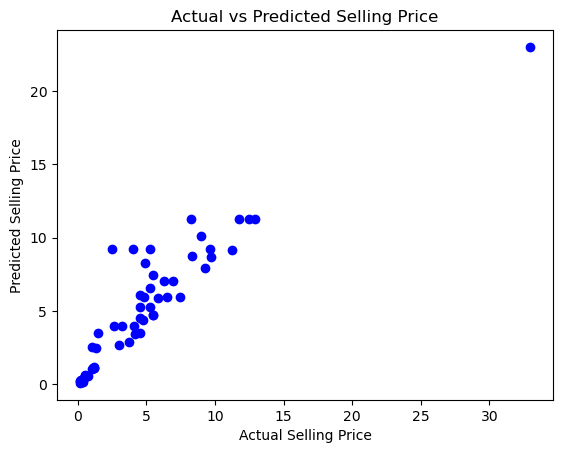

In [39]:
best_predictions = [
    Y_pred_lr,
    Y_pred_dt,
    Y_pred_rf
][best_index]

plt.scatter(Y_test, best_predictions, color="blue")

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")

plt.show()

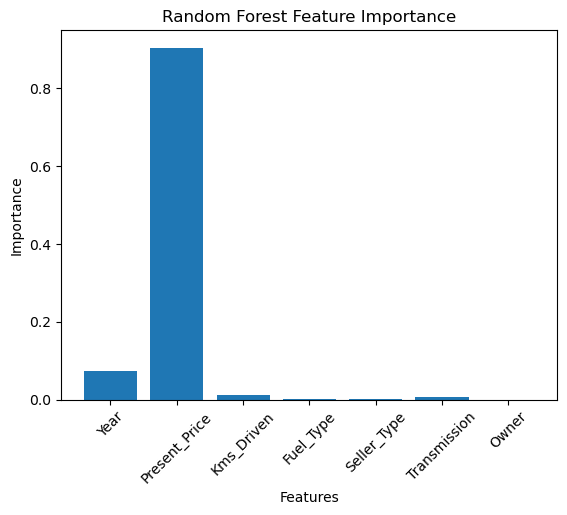

In [40]:
importance = rf.feature_importances_

plt.bar(X.columns, importance)

plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")

plt.show()

## Conclusion
After running all the cells, write a short conclusion based on the results:
- The dataset was loaded and explored using Pandas.
- Duplicate records were removed and categorical columns were encoded.
- Linear Regression, Decision Tree Regressor, and Random Forest Regressor were trained.
- Their performance was compared using MAE, MSE, RMSE, and R² Score.
- The best model was selected, actual and predicted prices were plotted, and feature importance was examined.